# Spam Mail Detector
### Internship Task 2 - Machine Learning

Classifying SMS messages as spam or ham from their text.

## Imports

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from sklearn.pipeline import make_pipeline

## Load the data

Loading the SMS dataset, checking missing values, and dropping duplicate rows.

In [2]:
# quoting=3 so messages containing quote characters are not merged
df = pd.read_csv('SMSSpamCollection.tsv', sep='\t', header=None, names=['label', 'message'], quoting=3)
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print('Shape:', df.shape)
print('\nMissing values:\n', df.isnull().sum())
print('\nClass counts:\n', df['label'].value_counts())
print(f'\nSpam percentage: {(df["label"] == "spam").mean() * 100:.2f}%')

Shape: (5574, 2)

Missing values:
 label      0
message    0
dtype: int64

Class counts:
 label
ham     4827
spam     747
Name: count, dtype: int64

Spam percentage: 13.40%


In [4]:
duplicate_count = df.duplicated(subset=['message']).sum()
print(f'Duplicate messages found: {duplicate_count}')

# Drop duplicate messages so the same text does not appear in both train and test sets
df = df.drop_duplicates(subset=['message']).reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)
print('\nClass percentages after dropping duplicates:')
print((df['label'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

Duplicate messages found: 403
Shape after dropping duplicates: (5171, 2)

Class percentages after dropping duplicates:
label
ham     87.37%
spam    12.63%
Name: proportion, dtype: object


## Exploring the data

Plotting the class balance, message lengths, and most frequent words.

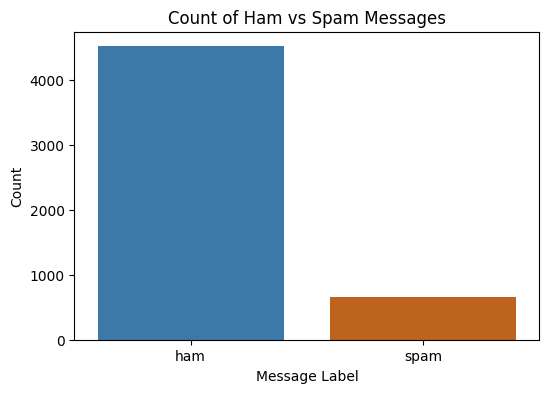

In [5]:
palette = {'ham': '#2b7bba', 'spam': '#d95f02'}

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', hue='label', palette=palette, legend=False)
plt.title('Count of Ham vs Spam Messages')
plt.xlabel('Message Label')
plt.ylabel('Count')
plt.show()

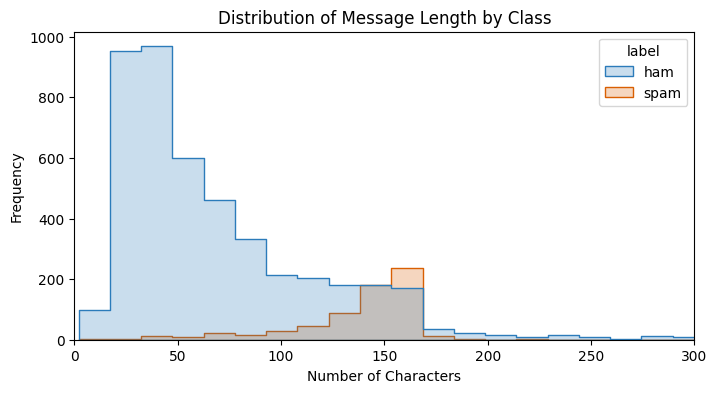

In [6]:
df['char_length'] = df['message'].apply(len)

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='char_length', hue='label', bins=60, palette=palette, element='step')
plt.title('Distribution of Message Length by Class')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.xlim(0, 300)
plt.show()

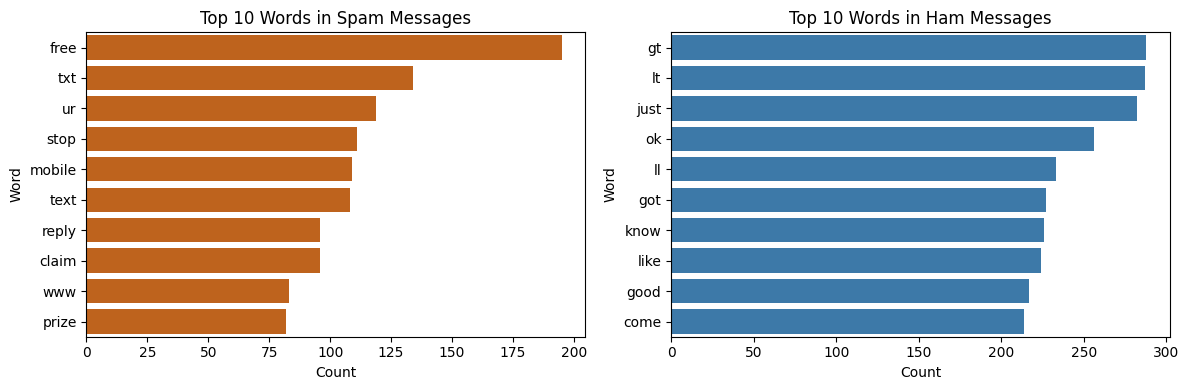

In [7]:
vec_spam = CountVectorizer(stop_words='english')
X_spam = vec_spam.fit_transform(df[df['label'] == 'spam']['message'])
spam_counts = pd.Series(X_spam.sum(axis=0).tolist()[0], index=vec_spam.get_feature_names_out()).sort_values(ascending=False).head(10)

vec_ham = CountVectorizer(stop_words='english')
X_ham = vec_ham.fit_transform(df[df['label'] == 'ham']['message'])
ham_counts = pd.Series(X_ham.sum(axis=0).tolist()[0], index=vec_ham.get_feature_names_out()).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=spam_counts.values, y=spam_counts.index, ax=axes[0], color='#d95f02')
axes[0].set_title('Top 10 Words in Spam Messages')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Word')

sns.barplot(x=ham_counts.values, y=ham_counts.index, ax=axes[1], color='#2b7bba')
axes[1].set_title('Top 10 Words in Ham Messages')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Word')

plt.tight_layout()
plt.show()

Observations from the exploratory plots:
- The dataset is imbalanced: ham messages make up 87.37% of the data, while spam messages make up 12.63%.
- Spam messages tend to be longer than ham messages, clustering between 130 and 160 characters.
- Ham messages are shorter on average, with most having fewer than 100 characters.
- Spam messages frequently contain promotional terms like "free", "txt", "ur", "stop", "mobile", and "text", while ham messages contain everyday words like "just", "ok", "got", "know", and "like".

## Text preprocessing

Cleaning message text and encoding labels as binary numbers.

In [8]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = ' '.join(text.split())
    return text

df['clean_message'] = df['message'].apply(clean_text)

In [9]:
for i in range(4):
    print(f'Original: {df.loc[i, "message"]}')
    print(f'Cleaned:  {df.loc[i, "clean_message"]}\n')

Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned:  go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat

Original: Ok lar... Joking wif u oni...
Cleaned:  ok lar joking wif u oni

Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned:  free entry in a wkly comp to win fa cup final tkts st may text fa to to receive entry questionstd txt ratetcs apply overs

Original: U dun say so early hor... U c already then say...
Cleaned:  u dun say so early hor u c already then say



Tokenization and stop word removal are handled by TfidfVectorizer(stop_words='english').

In [10]:
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})
df[['label', 'label_num']].head()

,label,label_num
0,ham,0
1,ham,0
2,spam,1
3,ham,0
4,ham,0


## Train/test split and features

Splitting into train and test sets, then fitting TF-IDF on training text only.

In [11]:
X = df['clean_message']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit vectorizer only on X_train to prevent data leakage from the test set
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f'Training set size: {X_train.shape[0]}')
print(f'Testing set size:  {X_test.shape[0]}')
print(f'Vocabulary size:   {len(tfidf.vocabulary_)}')

Training set size: 4136
Testing set size:  1035
Vocabulary size:   7275


## Model training

Fitting Naive Bayes and Logistic Regression on TF-IDF features.

In [12]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000, random_state=42)

## Evaluation

Evaluating the TF-IDF models on the test set using metrics and confusion matrices.

In [13]:
nb_preds = nb_model.predict(X_test_tfidf)
lr_preds = lr_model.predict(X_test_tfidf)

print('Multinomial Naive Bayes Metrics (Spam as Positive Class):')
print(f'Accuracy:  {accuracy_score(y_test, nb_preds):.4f}')
print(f'Precision: {precision_score(y_test, nb_preds):.4f}')
print(f'Recall:    {recall_score(y_test, nb_preds):.4f}')
print(f'F1 Score:  {f1_score(y_test, nb_preds):.4f}')
print('\nClassification Report:\n')
print(classification_report(y_test, nb_preds, target_names=['ham', 'spam']))

Multinomial Naive Bayes Metrics (Spam as Positive Class):
Accuracy:  0.9623
Precision: 0.9894
Recall:    0.7099
F1 Score:  0.8267

Classification Report:

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       0.99      0.71      0.83       131

    accuracy                           0.96      1035
   macro avg       0.97      0.85      0.90      1035
weighted avg       0.96      0.96      0.96      1035



In [14]:
print('Logistic Regression Metrics (Spam as Positive Class):')
print(f'Accuracy:  {accuracy_score(y_test, lr_preds):.4f}')
print(f'Precision: {precision_score(y_test, lr_preds):.4f}')
print(f'Recall:    {recall_score(y_test, lr_preds):.4f}')
print(f'F1 Score:  {f1_score(y_test, lr_preds):.4f}')
print('\nClassification Report:\n')
print(classification_report(y_test, lr_preds, target_names=['ham', 'spam']))

Logistic Regression Metrics (Spam as Positive Class):
Accuracy:  0.9478
Precision: 0.9873
Recall:    0.5954
F1 Score:  0.7429

Classification Report:

              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       904
        spam       0.99      0.60      0.74       131

    accuracy                           0.95      1035
   macro avg       0.97      0.80      0.86      1035
weighted avg       0.95      0.95      0.94      1035



Accuracy alone is misleading because 87.37% of messages are ham; predicting everything as ham would give high accuracy while missing all spam.

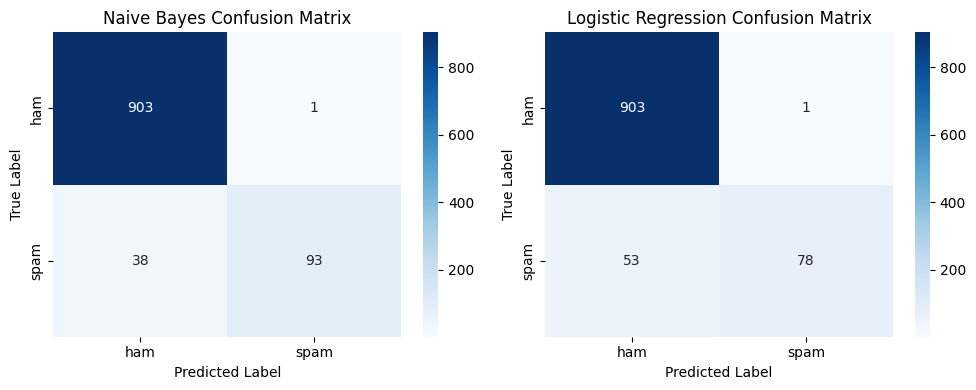

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_nb = confusion_matrix(y_test, nb_preds)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
axes[0].set_title('Naive Bayes Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

cm_lr = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [16]:
comparison_df = pd.DataFrame({
    'Model': ['Multinomial Naive Bayes', 'Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, nb_preds), accuracy_score(y_test, lr_preds)],
    'Precision': [precision_score(y_test, nb_preds), precision_score(y_test, lr_preds)],
    'Recall': [recall_score(y_test, nb_preds), recall_score(y_test, lr_preds)],
    'F1 Score': [f1_score(y_test, nb_preds), f1_score(y_test, lr_preds)]
})
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.962319,0.989362,0.709924,0.826667
1,Logistic Regression,0.947826,0.987342,0.595420,0.742857


In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

nb_pipeline = make_pipeline(TfidfVectorizer(stop_words='english'), MultinomialNB())
lr_pipeline = make_pipeline(TfidfVectorizer(stop_words='english'), LogisticRegression(max_iter=1000, random_state=42))

nb_cv_scores = cross_val_score(nb_pipeline, X, y, cv=cv, scoring='f1')
lr_cv_scores = cross_val_score(lr_pipeline, X, y, cv=cv, scoring='f1')

cv_df = pd.DataFrame({
    'Model': ['Multinomial Naive Bayes', 'Logistic Regression'],
    'CV Mean F1': [nb_cv_scores.mean(), lr_cv_scores.mean()],
    'CV Std F1': [nb_cv_scores.std(), lr_cv_scores.std()]
})
cv_df

,Model,CV Mean F1,CV Std F1
0,Multinomial Naive Bayes,0.806210,0.030833
1,Logistic Regression,0.782849,0.015992


## Bag of Words vs TF-IDF

Comparing test set metrics and cross-validation between TF-IDF and Bag of Words.

In [18]:
# Fit CountVectorizer on training text only to prevent data leakage
bow = CountVectorizer(stop_words='english')
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

nb_bow = MultinomialNB()
nb_bow.fit(X_train_bow, y_train)
nb_bow_preds = nb_bow.predict(X_test_bow)

lr_bow = LogisticRegression(max_iter=1000, random_state=42)
lr_bow.fit(X_train_bow, y_train)
lr_bow_preds = lr_bow.predict(X_test_bow)

# 4-combination test set metrics table
bow_comparison_df = pd.DataFrame([
    {
        'Model': 'Naive Bayes (TF-IDF)',
        'Accuracy': accuracy_score(y_test, nb_preds),
        'Precision': precision_score(y_test, nb_preds),
        'Recall': recall_score(y_test, nb_preds),
        'F1 Score': f1_score(y_test, nb_preds)
    },
    {
        'Model': 'Logistic Regression (TF-IDF)',
        'Accuracy': accuracy_score(y_test, lr_preds),
        'Precision': precision_score(y_test, lr_preds),
        'Recall': recall_score(y_test, lr_preds),
        'F1 Score': f1_score(y_test, lr_preds)
    },
    {
        'Model': 'Naive Bayes (Bag of Words)',
        'Accuracy': accuracy_score(y_test, nb_bow_preds),
        'Precision': precision_score(y_test, nb_bow_preds),
        'Recall': recall_score(y_test, nb_bow_preds),
        'F1 Score': f1_score(y_test, nb_bow_preds)
    },
    {
        'Model': 'Logistic Regression (Bag of Words)',
        'Accuracy': accuracy_score(y_test, lr_bow_preds),
        'Precision': precision_score(y_test, lr_bow_preds),
        'Recall': recall_score(y_test, lr_bow_preds),
        'F1 Score': f1_score(y_test, lr_bow_preds)
    }
])
bow_comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes (TF-IDF),0.962319,0.989362,0.709924,0.826667
1,Logistic Regression (TF-IDF),0.947826,0.987342,0.595420,0.742857
2,Naive Bayes (Bag of Words),0.978744,0.943089,0.885496,0.913386
3,Logistic Regression (Bag of Words),0.973913,0.990566,0.801527,0.886076


In [19]:
nb_bow_pipeline = make_pipeline(CountVectorizer(stop_words='english'), MultinomialNB())
lr_bow_pipeline = make_pipeline(CountVectorizer(stop_words='english'), LogisticRegression(max_iter=1000, random_state=42))

nb_bow_cv_scores = cross_val_score(nb_bow_pipeline, X, y, cv=cv, scoring='f1')
lr_bow_cv_scores = cross_val_score(lr_bow_pipeline, X, y, cv=cv, scoring='f1')

cv_all_df = pd.DataFrame([
    {'Model': 'Naive Bayes (TF-IDF)', 'CV Mean F1': nb_cv_scores.mean(), 'CV Std F1': nb_cv_scores.std()},
    {'Model': 'Logistic Regression (TF-IDF)', 'CV Mean F1': lr_cv_scores.mean(), 'CV Std F1': lr_cv_scores.std()},
    {'Model': 'Naive Bayes (Bag of Words)', 'CV Mean F1': nb_bow_cv_scores.mean(), 'CV Std F1': nb_bow_cv_scores.std()},
    {'Model': 'Logistic Regression (Bag of Words)', 'CV Mean F1': lr_bow_cv_scores.mean(), 'CV Std F1': lr_bow_cv_scores.std()},
])
cv_all_df

,Model,CV Mean F1,CV Std F1
0,Naive Bayes (TF-IDF),0.806210,0.030833
1,Logistic Regression (TF-IDF),0.782849,0.015992
2,Naive Bayes (Bag of Words),0.918330,0.008711
3,Logistic Regression (Bag of Words),0.893325,0.018001


## Looking at the mistakes

Examining misclassified messages from the best performing model.

In [20]:
test_analysis = pd.DataFrame({
    'original_message': df.loc[y_test.index, 'message'].values,
    'clean_message': X_test.values,
    'true_label': ['ham' if v == 0 else 'spam' for v in y_test.values],
    'predicted_label': ['ham' if v == 0 else 'spam' for v in nb_bow_preds]
})

nb_bow_errors = test_analysis[test_analysis['true_label'] != test_analysis['predicted_label']]
print(f'Total errors: {len(nb_bow_errors)}')
print(f'False positives: {(nb_bow_errors["predicted_label"] == "spam").sum()}')
print(f'False negatives: {(nb_bow_errors["predicted_label"] == "ham").sum()}')

nb_bow_errors[['true_label', 'predicted_label', 'original_message']].head(5)

Total errors: 22
False positives: 7
False negatives: 15


,true_label,predicted_label,original_message
121,spam,ham,"FreeMsg Hey U, i just got 1 of these video/pic..."
128,ham,spam,Are you free now?can i call now?
141,spam,ham,Check Out Choose Your Babe Videos @ sms.shsex....
210,ham,spam,Nokia phone is lovly..
223,spam,ham,Xmas & New Years Eve tickets are now on sale f...


Naive Bayes with Bag of Words made 22 errors on the test set, with 7 false positives and 15 false negatives. The false positives contain words commonly seen in spam like "free" or phone brand names, while false negatives often lack strong spam keywords or had key indicators removed during cleaning.

## Predict on new messages

Testing the trained model on a few sample messages to verify predictions.

In [21]:
new_messages = [
    'Congratulations! You have won a 1000 dollar gift card. Call now or text CLAIM to 88888 to receive your prize.',
    'Hey, are we still meeting at the library around 4 pm to finish the assignment?',
    'URGENT! Your mobile account has been credited with 500 bonus points. Reply STOP to opt out.',
    'Ill be home late tonight, can you please save some dinner for me?'
]

clean_new = [clean_text(msg) for msg in new_messages]
new_bow = bow.transform(clean_new)
new_preds = nb_bow.predict(new_bow)

for msg, pred in zip(new_messages, new_preds):
    label = 'spam' if pred == 1 else 'ham'
    print(f'[{label.upper()}] {msg}')

[SPAM] Congratulations! You have won a 1000 dollar gift card. Call now or text CLAIM to 88888 to receive your prize.
[HAM] Hey, are we still meeting at the library around 4 pm to finish the assignment?
[SPAM] URGENT! Your mobile account has been credited with 500 bonus points. Reply STOP to opt out.
[HAM] Ill be home late tonight, can you please save some dinner for me?


## Conclusion

- Multinomial Naive Bayes with Bag of Words performed best overall, reaching a test F1 score of 0.9134 and 97.87% accuracy, beating TF-IDF Naive Bayes by 0.0867 in F1.
- For the best model, precision was 0.9431 and recall was 0.8855, resulting in 7 real messages marked as spam and 15 missed spam messages.
- The 5-fold cross-validation confirmed Naive Bayes with Bag of Words was best, with a mean F1 of 0.9183 (std 0.0087), followed by Logistic Regression with Bag of Words at 0.8933 (std 0.0180).
- Bag of Words did better than TF-IDF across both models; I did not test why, but one possible reason is that simple count features may preserve stronger frequency signals in short texts without inverse frequency penalties.
- Because clean_text removes all digits and symbols, useful spam signals like phone numbers and currency marks are lost, so keeping them or adding character n-grams could help.